In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

df=pd.read_csv("/content/Bengaluru_House_Data.csv", na_values=["?", "NA", "N/A", "-", "", "null", "unknown"])

df.columns=df.columns.str.strip().str.lower().str.replace(" ", "_")
raw=df.copy()
TARGET="price"


In [2]:
print("Shape:", df.shape, "| Duplicates:", df.duplicated().sum())
df.info()
pd.DataFrame({"missing_%": (df.isna().mean() * 100).round(1),
              "unique": df.nunique(),
              "example": df.iloc[0]})

Shape: (13320, 9) | Duplicates: 529
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


,missing_%,unique,example
area_type,0.0,4,Super built-up Area
availability,0.0,81,19-Dec
location,0.0,1305,Electronic City Phase II
size,0.1,31,2 BHK
society,41.3,2688,Coomee
total_sqft,0.0,2117,1056
bath,0.5,19,2.0
balcony,4.6,4,1.0
price,0.0,1994,39.07


In [5]:
df.sample(5, random_state=1)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
5854,Super built-up Area,Ready To Move,Yelahanka,2 BHK,Neite T,1200,2.0,1.0,54.0
7124,Super built-up Area,Ready To Move,KR Puram,2 BHK,Thisea,1200,2.0,1.0,42.0
8528,Plot Area,Ready To Move,poornaprajna layout,2 Bedroom,NaN,900,2.0,0.0,128.0
11109,Super built-up Area,18-Jul,Rajaji Nagar,2 BHK,ProdsWe,1376,2.0,1.0,124.0
8180,Super built-up Area,Ready To Move,HSR Layout,2 BHK,Siestr,1142,2.0,2.0,65.0


In [7]:
df=df.drop_duplicates()
df=df.drop(columns=["society"])
print(df.shape)

(12791, 8)


size → bhk (text → number)


In [8]:
df["bhk"]=df["size"].str.extract(r"(\d+)")[0].astype(float)

In [9]:
rng = df["total_sqft"].str.extract(r"(\d+\.?\d*)\s*-\s*(\d+\.?\d*)").astype(float)
df["total_sqft"] = rng.mean(axis=1).fillna(pd.to_numeric(df["total_sqft"], errors="coerce"))

availability → one useful fact

In [10]:
df["ready_to_move"] = (df["availability"] == "Ready To Move").astype(int)
df = df.drop(columns=["size", "availability"])

In [11]:
for c in df.select_dtypes("object"):
    df[c] = df[c].str.strip().str.lower()

Too many locations → group the rare ones

In [12]:
print(df["location"].nunique(), "locations before")
counts = df["location"].value_counts()
df["location"] = df["location"].where(df["location"].map(counts) > 10, "other")
print(df["location"].nunique(), "locations after")

1283 locations before
234 locations after


Impossible values (use common sense)

In [13]:
before = len(df)
df = df[((df["total_sqft"] / df["bhk"]) >= 300) | df["total_sqft"].isna() | df["bhk"].isna()]
df = df[(df["bath"] <= df["bhk"] + 2) | df["bath"].isna() | df["bhk"].isna()]
print("Removed", before - len(df), "impossible rows")

Removed 743 impossible rows


missing value

In [14]:
print(df.isna().sum()[df.isna().sum() > 0])

total_sqft     46
bath           73
balcony       512
bhk            16
dtype: int64


In [15]:
df = df.dropna(subset=[TARGET, "bhk", "total_sqft"])   # core columns: don't guess

num_cols = df.select_dtypes("number").columns.drop(TARGET, errors="ignore")
cat_cols = df.select_dtypes("object").columns

for c in num_cols:
    if df[c].isna().mean() > 0.05:                      # many missing -> keep a flag
        df[c + "_missing"] = df[c].isna().astype(int)
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].fillna("unknown")

outliers and skew

In [16]:
num_cols = df.select_dtypes("number").columns.drop(TARGET, errors="ignore")
for c in list(num_cols) + [TARGET]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c:15} outliers={n:5}  skew={df[c].skew():.2f}  max={df[c].max()}")

total_sqft      outliers= 1094  skew=15.22  max=52272.0
bath            outliers=  662  skew=2.07  max=16.0
balcony         outliers=    0  skew=-0.04  max=3.0
bhk             outliers=  382  skew=1.94  max=16.0
ready_to_move   outliers= 2563  skew=-1.40  max=1
price           outliers= 1203  skew=7.38  max=2912.0


In [17]:
df["total_sqft"] = df["total_sqft"].clip(upper=df["total_sqft"].quantile(0.99))
df["log_target"] = np.log1p(df[TARGET])

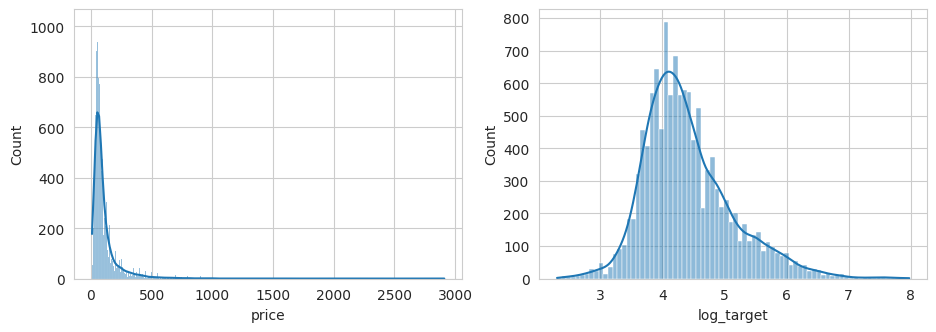

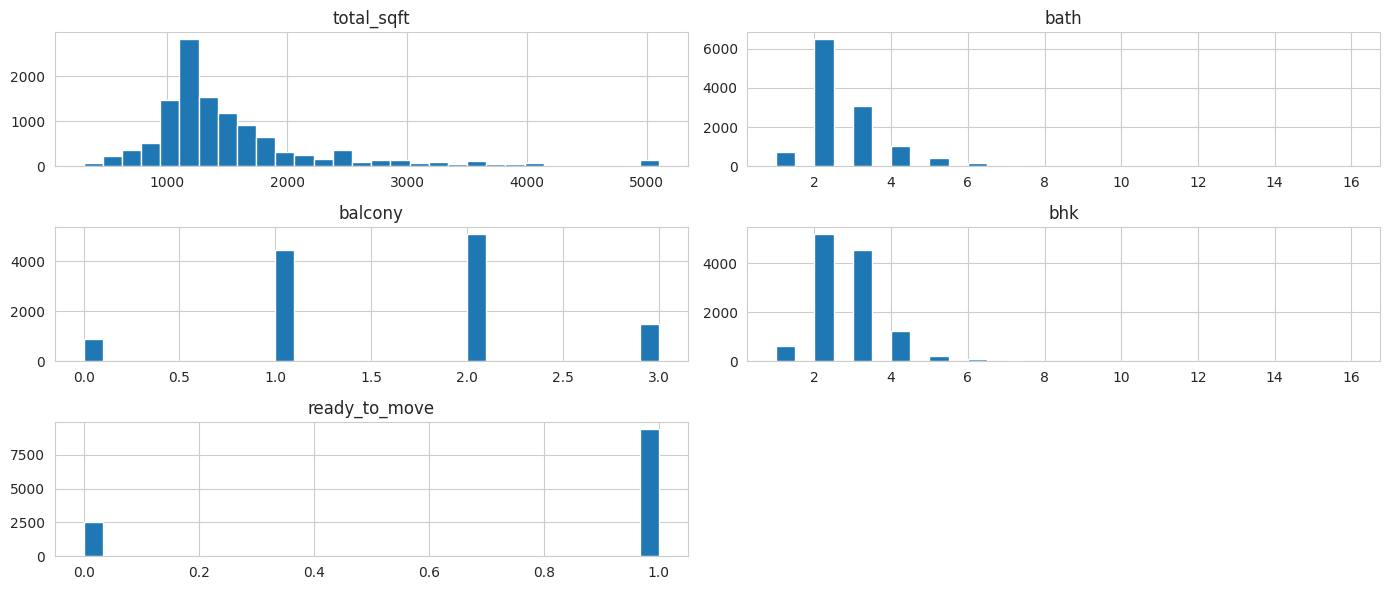

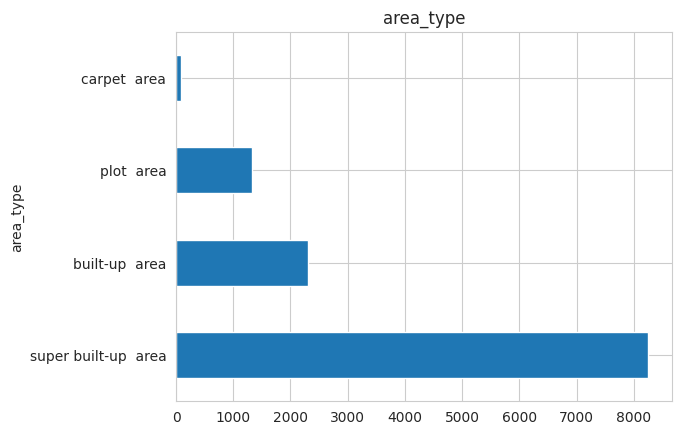

ready_to_move    0.034645
balcony          0.124813
bhk              0.479759
bath             0.517866
total_sqft       0.691925
dtype: float64
area_type
super built-up  area     65.255
carpet  area             69.545
built-up  area           70.000
plot  area              160.000
Name: price, dtype: float64


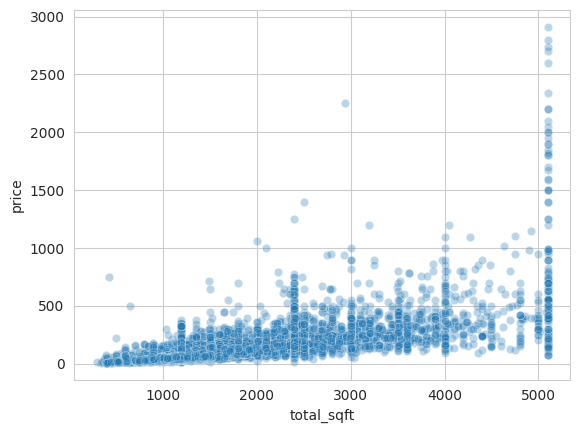

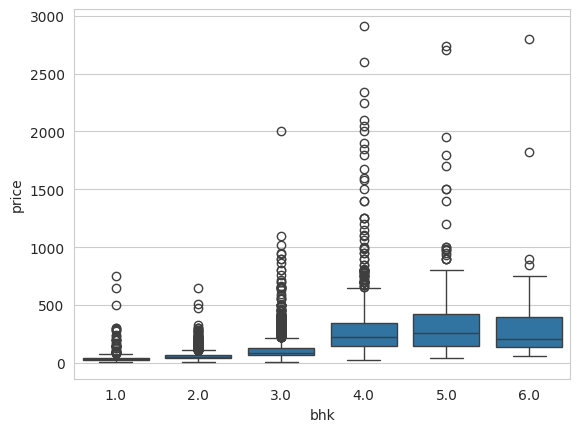

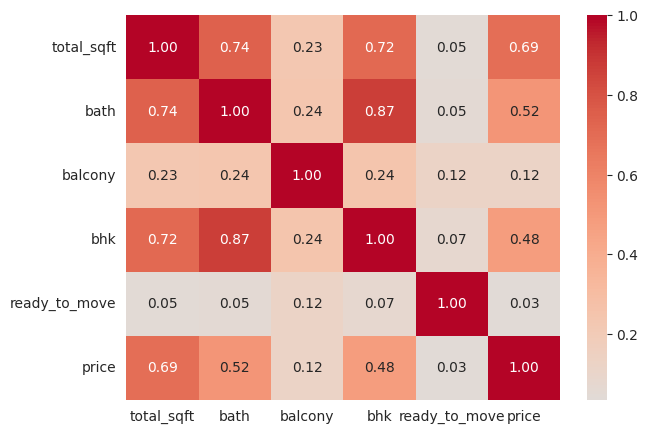

In [18]:
# 1. What does the target look like?
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df[TARGET], kde=True, ax=ax[0]); sns.histplot(df["log_target"], kde=True, ax=ax[1])
plt.show()

# 2. What does each feature look like?
df[num_cols].hist(bins=30, figsize=(14, 6)); plt.tight_layout(); plt.show()

# 3. Small categorical features
for c in cat_cols:
    if df[c].nunique() <= 15:
        df[c].value_counts().plot.barh(title=c); plt.show()

# 4. What relates to the target?
print(df[num_cols].corrwith(df[TARGET]).sort_values())
print(df.groupby("area_type")[TARGET].median().sort_values())
sns.scatterplot(x="total_sqft", y=TARGET, data=df, alpha=0.3); plt.show()
sns.boxplot(x="bhk", y=TARGET, data=df[df["bhk"] <= 6]); plt.show()

# 5. What relates to each other?
plt.figure(figsize=(7, 5))
sns.heatmap(df[list(num_cols) + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

In [19]:
print(f"Raw {raw.shape} -> clean {df.shape}")
df.to_csv("bengaluru_clean.csv", index=False)

Raw (13320, 9) -> clean (11986, 9)
